In [27]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [28]:
df = pd.read_csv("/content/AB_NYC_2019.csv")

In [29]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [31]:
df.shape

(48895, 16)

In [32]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


In [33]:
df.describe(include = 'object')

,name,host_name,neighbourhood_group,neighbourhood,room_type,last_review
count,48879,48874,48895,48895,48895,38843
unique,47905,11452,5,221,3,1764
top,Hillside Hotel,Michael,Manhattan,Williamsburg,Entire home/apt,2019-06-23
freq,18,417,21661,3920,25409,1413


In [34]:
df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [35]:
(df.isnull().sum()/len(df))*100

,0
id,0.000000
name,0.032723
host_id,0.000000
host_name,0.042949
neighbourhood_group,0.000000
neighbourhood,0.000000
latitude,0.000000
longitude,0.000000
room_type,0.000000
price,0.000000


In [36]:
df.drop(columns=['id','host_id','host_name'], inplace =True)

In [45]:
df.drop(columns= ['name'],inplace = True)

In [37]:
df.drop(columns=['last_review'],inplace = True)

In [38]:
df[df['reviews_per_month'].isnull()]

,name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
2,THE VILLAGE OF HARLEM....NEW YORK !,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,1,365
19,Huge 2 BR Upper East Cental Park,Manhattan,East Harlem,40.79685,-73.94872,Entire home/apt,190,7,0,NaN,2,249
26,Magnifique Suite au N de Manhattan - vue Cloitres,Manhattan,Inwood,40.86754,-73.92639,Private room,80,4,0,NaN,1,0
36,Clean and Quiet in Brooklyn,Brooklyn,Bedford-Stuyvesant,40.68876,-73.94312,Private room,35,60,0,NaN,1,365
38,Country space in the city,Brooklyn,Flatbush,40.63702,-73.96327,Private room,150,1,0,NaN,1,365
...,...,...,...,...,...,...,...,...,...,...,...,...
48890,Charming one bedroom - newly renovated rowhouse,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,2,9
48891,Affordable room in Bushwick/East Williamsburg,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,2,36
48892,Sunny Studio at Historical Neighborhood,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,1,27
48893,43rd St. Time Square-cozy single bed,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,6,2


In [39]:
df[df['reviews_per_month'].isnull()][['number_of_reviews', 'reviews_per_month']]

,number_of_reviews,reviews_per_month
2,0,NaN
19,0,NaN
26,0,NaN
36,0,NaN
38,0,NaN
...,...,...
48890,0,NaN
48891,0,NaN
48892,0,NaN
48893,0,NaN


In [40]:
df['reviews_per_month'].fillna(0, inplace=True)

/tmp/ipykernel_3561/1792330394.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['reviews_per_month'].fillna(0, inplace=True)


In [41]:
df.duplicated().sum()

np.int64(0)

In [66]:
df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 45759 entries, 0 to 48894
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   latitude                           45759 non-null  float64
 1   longitude                          45759 non-null  float64
 2   price                              45759 non-null  int64  
 3   minimum_nights                     45759 non-null  int64  
 4   number_of_reviews                  45759 non-null  int64  
 5   reviews_per_month                  45759 non-null  float64
 6   calculated_host_listings_count     45759 non-null  int64  
 7   availability_365                   45759 non-null  int64  
 8   neighbourhood_group_Brooklyn       45759 non-null  bool   
 9   neighbourhood_group_Manhattan      45759 non-null  bool   
 10  neighbourhood_group_Queens         45759 non-null  bool   
 11  neighbourhood_group_Staten Island  45759 non-null  bool   


In [47]:
df.drop(columns=['neighbourhood'], inplace=True)

In [48]:
df = pd.get_dummies(
    df,
    columns=['neighbourhood_group','room_type'],
    drop_first = True
)

In [49]:
df['price'].describe()

,price
count,48895.000000
mean,152.720687
std,240.154170
min,0.000000
25%,69.000000
50%,106.000000
75%,175.000000
max,10000.000000


In [50]:
df['minimum_nights'].describe()

,minimum_nights
count,48895.000000
mean,7.029962
std,20.510550
min,1.000000
25%,1.000000
50%,3.000000
75%,5.000000
max,1250.000000


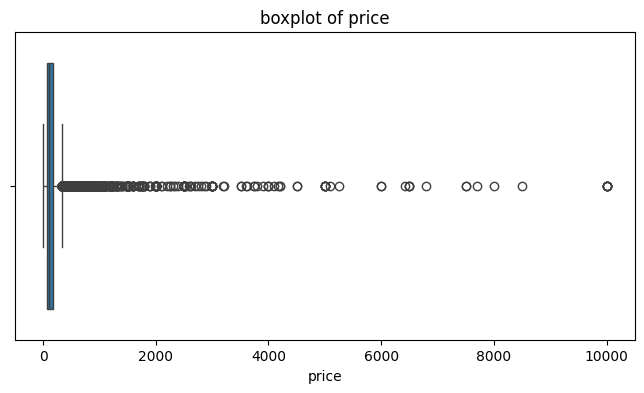

In [56]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df['price'])
plt.title("boxplot of price")
plt.show()

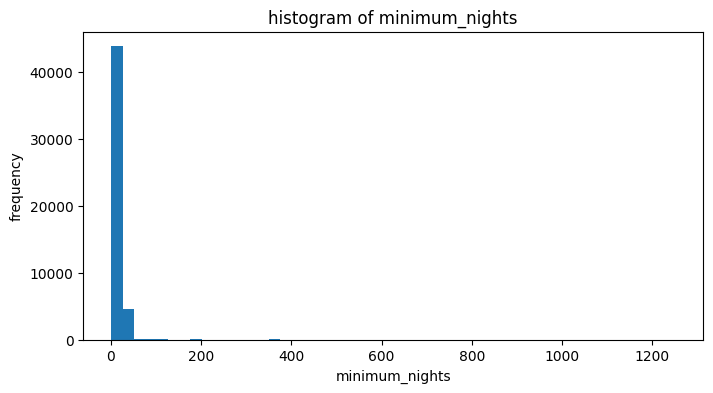

In [59]:
plt.figure(figsize=(8,4))
plt.hist(df['minimum_nights'], bins=50)
plt.title("histogram of minimum_nights")
plt.xlabel("minimum_nights")
plt.ylabel("frequency")
plt.show()

In [60]:
price_limit = df['price'].quantile(0.95)
nights_limit = df['minimum_nights'].quantile(0.95)
print("price 95 percentile",price_limit)
print("minimum nights 95 percentile:",nights_limit)

price 95 percentile 355.0
minimum nights 95 percentile: 30.0


In [61]:
df = df[(df['price'] <= price_limit) & (df['minimum_nights'] <= nights_limit)]

In [62]:
df['price'] <= price_limit

,price
0,True
1,True
2,True
3,True
4,True
...,...
48890,True
48891,True
48892,True
48893,True


In [63]:
df['minimum_nights'] <= nights_limit

,minimum_nights
0,True
1,True
2,True
3,True
4,True
...,...
48890,True
48891,True
48892,True
48893,True


In [64]:
print(df.shape)

(45759, 14)


In [65]:
print(df['price'].max())
print(df['minimum_nights'].max())

355
30


In [68]:
X = df.drop('price',axis=1)
y = df['price']

In [70]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test  = train_test_split(
    X,y,test_size=0.2,random_state=42)


In [75]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [71]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()

In [72]:
model.fit(X_train, y_train)

LinearRegression()

In [73]:
y_pred = model.predict(X_test)

In [74]:
from sklearn.metrics import r2_score, mean_absolute_error,mean_squared_error

In [76]:
print("Mean Squared Error:",mean_squared_error(y_test,y_pred))
print("R2 score:",r2_score(y_test,y_pred))
print("Mean Absolute Error:",mean_absolute_error(y_test,y_pred))

Mean Squared Error: 2834.959378892661
R2 score: 0.47082773500021025
Mean Absolute Error: 38.5408749155387


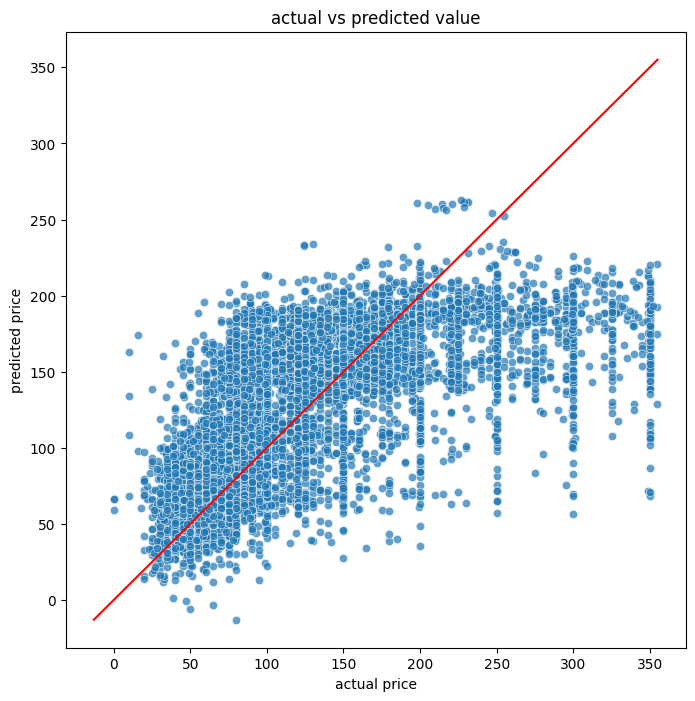

In [77]:
plt.figure(figsize=(8,8))
sns.scatterplot(x=y_test,y=y_pred,alpha = 0.7)
plt.xlabel("actual price")
plt.ylabel("predicted price")
plt.title("actual vs predicted value")
minimum = min(min(y_test),min(y_pred))
maximum = max(max(y_test),max(y_pred))
plt.plot([minimum,maximum],[minimum,maximum],color="red")
plt.show()


In [79]:
residuals = y_test - y_pred

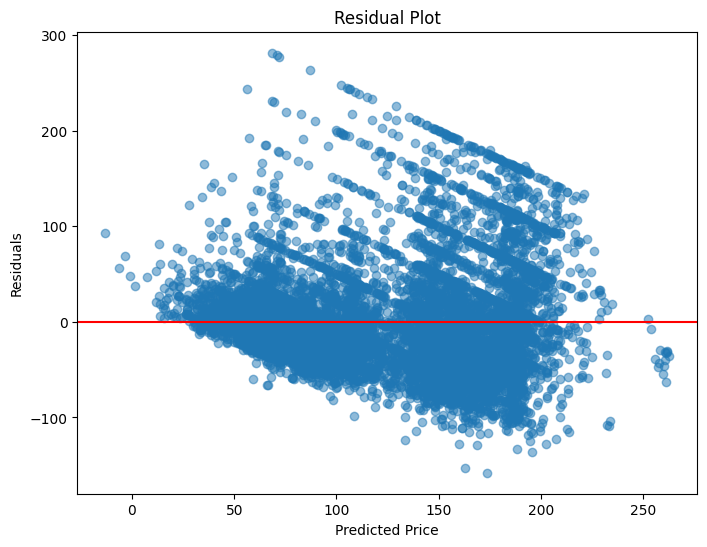

In [80]:
plt.figure(figsize=(8,6))
plt.scatter(y_pred, residuals, alpha=0.5)

plt.axhline(y=0, color='red')

plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()


The model performs better on cheaper and moderately priced listings. In the Actual vs Predicted graph, points for lower-priced listings are closer to the ideal diagonal line, indicating smaller prediction errors. For expensive listings, the points are farther from the line, showing larger errors. This happens because expensive Airbnb prices depend on additional factors such as luxury amenities, interior quality, and special features that are not included in the dataset.